## 1. Data Preparation
Data preparation & feature engineering for S&P 500 next-day close prediction. Sources used:
* Kaggle sp500_index.csv (primary, Close only, up to 2024-12-20)
* FRED SP500 series (Close only, used to extend coverage to 2026-03-12)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy import stats
import matplotlib.dates as mdates

#### LOADING AND MERGING THE DATASETS

In [2]:
#-----------------------------------------------
#Load the Kaggle sp500_index dataset
#-----------------------------------------------
index = pd.read_csv("Downloads/sp500_index.csv", sep = ",")
index.columns = ["Date", "Close"]
index["Date"] = pd.to_datetime(index["Date"]) #converts values into a proper date/time format.
index.head()

print("Missing values:", index.isnull().sum())

Missing values: Date     0
Close    0
dtype: int64


In [3]:
#----------------------------------------------
#Load the FRED SP500 dataset
#----------------------------------------------
fred = pd.read_csv("Downloads/SP500.csv", sep = ",")
fred.columns = ["Date", "Close"]
fred["Date"] = pd.to_datetime(fred["Date"])

print("Missing value:", fred.isnull().sum())

Missing value: Date      0
Close    50
dtype: int64


In [4]:
#----------------------------------------------
#Remove missing values
#----------------------------------------------
fred = fred.dropna(subset=["Close"]) 

In [5]:
#------------------------------------------------------------------------
#Restrict to the proposal's sampling frame: 2024-01-01 to 2026-03-12
#------------------------------------------------------------------------
data = pd.concat([index, fred], ignore_index = True)
data = data.drop_duplicates(subset = "Date").sort_values("Date").reset_index(drop = True)
data = data[(data["Date"] >= "2024-01-01") & (data["Date"] <= "2026-03-12")].reset_index(drop = True)

print("Rows after merge & date filter:", len(data))
print("Date range:", data["Date"].min().date(), "to", data["Date"].max().date())
print("Missing values:", data.isnull().sum())
print("Duplicate values:", data.duplicated().sum())

Rows after merge & date filter: 550
Date range: 2024-01-02 to 2026-03-12
Missing values: Date     0
Close    0
dtype: int64
Duplicate values: 0


In [6]:
#----------------------------------------------------------------------------------------
#Data quality check for unusually large gaps between dates in the S&P 500 dataset.
#----------------------------------------------------------------------------------------
data["gap_days"] = data["Date"].diff().dt.days #Calculate the number of days between observations
gaps = data[data["gap_days"] > 4] #Find unusually large gaps
print(gaps[["Date", "gap_days"]].to_string(index = False) 
      if len(gaps) 
      else "No large gaps found between dates")

No large gaps found between dates


#### FEATURE ENGINEERING
7 features will be used as stated on the proposal

In [7]:
#----------------------------------------------
#Create a new DataFrame
#----------------------------------------------
df = data[["Date", "Close"]].copy()

df["MA5"] = df["Close"].rolling(window = 5).mean()
df["MA10"] = df["Close"].rolling(window = 10).mean()
df["Daily_Return_Pct"] = df["Close"].pct_change() * 100
df["Lag1"] = df["Close"].shift(1)
df["Lag2"] = df["Close"].shift(2)
df["Lag3"] = df["Close"].shift(3)
df["Daily_Price_Range"] = (df["Close"] - df["Close"].shift(1)).abs()

#------------------------------------------------------------------------------
#Create a target variable (The aim is to predict next-day closing price)
#------------------------------------------------------------------------------
df["Target_next-day"] = df["Close"].shift(-1)

rows_before = len(df)
df_clean = df.dropna().reset_index(drop = True)
rows_after = len(df_clean)
print(f"Rows before feature engineering dropna: {rows_before}")
print(f"Rows after dropna: {rows_after}")
print(f"Rows removed: {rows_before - rows_after}")

Rows before feature engineering dropna: 550
Rows after dropna: 540
Rows removed: 10


#### DESCRIPTIVE STATISTICS

In [8]:
cols = ["Close", "MA5", "MA10", "Daily_Return_Pct", "Daily_Price_Range"]
desc = df_clean[cols].agg(["mean", "median", "std", "skew", "min", "max"]).T
desc["kurtosis"] = df_clean[cols].kurt()
print(desc.round(3))

                       mean    median      std   skew       min       max  \
Close              5932.383  5893.100  612.990  0.148  4739.210  6978.600   
MA5                5924.983  5904.567  612.838  0.155  4770.040  6968.222   
MA10               5915.379  5896.644  613.334  0.159  4746.348  6942.083   
Daily_Return_Pct      0.069     0.103    0.991  0.694    -5.975     9.515   
Daily_Price_Range    38.432    29.100   41.047  3.931     0.020   474.130   

                   kurtosis  
Close                -1.095  
MA5                  -1.090  
MA10                 -1.068  
Daily_Return_Pct     18.658  
Daily_Price_Range    29.570  


#### SAVE THE ENGINEERED DATASET
This dataset will be used for further analysis

In [9]:
#----------------------------------------------
#Save the engineered dataset
#----------------------------------------------
df_clean.to_csv("C:/Users/kitso/engineered_dataset.csv", index = False)
desc.round(3).to_csv("C:/Users/kitso/descriptive_stats.csv")

## 2. Exploratory Data Analysis (EDA)

In [10]:
df = pd.read_csv("C:/Users/kitso/engineered_dataset.csv", sep = ",", parse_dates = ["Date"])
df.head()

,Date,Close,MA5,MA10,Daily_Return_Pct,Lag1,Lag2,Lag3,Daily_Price_Range,Target_next-day
0,2024-01-16,4765.98,4774.000,4746.710,-0.373132,4783.83,4780.24,4783.45,17.85,4739.21
1,2024-01-17,4739.21,4770.542,4746.348,-0.561689,4765.98,4783.83,4780.24,26.77,4780.94
2,2024-01-18,4780.94,4770.040,4753.961,0.880527,4739.21,4765.98,4783.83,41.73,4839.81
3,2024-01-19,4839.81,4781.954,4769.074,1.231348,4780.94,4739.21,4765.98,58.87,4850.43
4,2024-01-22,4850.43,4795.274,4784.393,0.219430,4839.81,4780.94,4739.21,10.62,4864.60


#### Plot 1: Price trend with moving averages

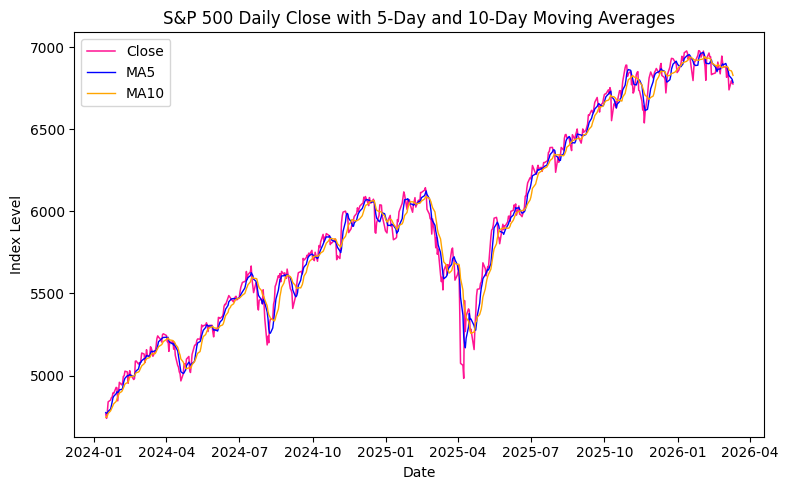

In [11]:
#----------------------------------------------
#Plot 1: Price trend with moving averages
#----------------------------------------------
fig, ax = plt.subplots(figsize = (8, 5))
ax.plot(df["Date"], df["Close"], label="Close", color="deeppink", linewidth=1.1)
ax.plot(df["Date"], df["MA5"], label="MA5", color="blue", linewidth=1)
ax.plot(df["Date"], df["MA10"], label="MA10", color="orange", linewidth=1)
ax.set_title("S&P 500 Daily Close with 5-Day and 10-Day Moving Averages")
ax.set_xlabel("Date")
ax.set_ylabel("Index Level")
ax.legend()
fig.tight_layout()
fig.savefig("C:/Users/kitso/plot1_price_trend.png")
plt.show()

#### Plot 2: Distribution of daily percentage return

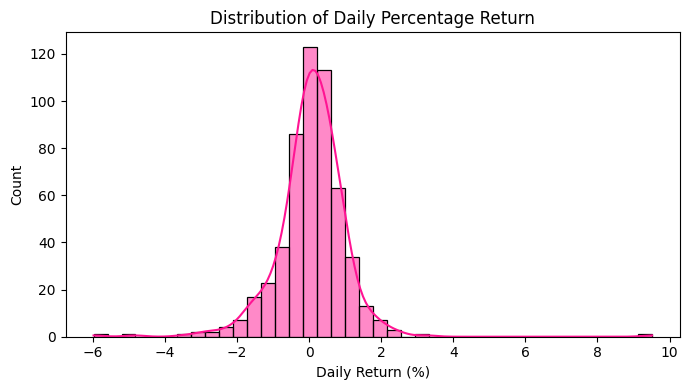

In [12]:
#----------------------------------------------------------
#Plot 2: Distribution of daily percentage return
#----------------------------------------------------------
fig, ax = plt.subplots(figsize = (7, 4))
sns.histplot(df["Daily_Return_Pct"], kde = True, bins = 40, color = "deeppink", ax = ax)
ax.set_title("Distribution of Daily Percentage Return")
ax.set_xlabel("Daily Return (%)")
fig.tight_layout()
fig.savefig("C:/Users/kitso/plot2_return_dist.png")
plt.show()

#### Plot 3: Correlation matrix of engineered features

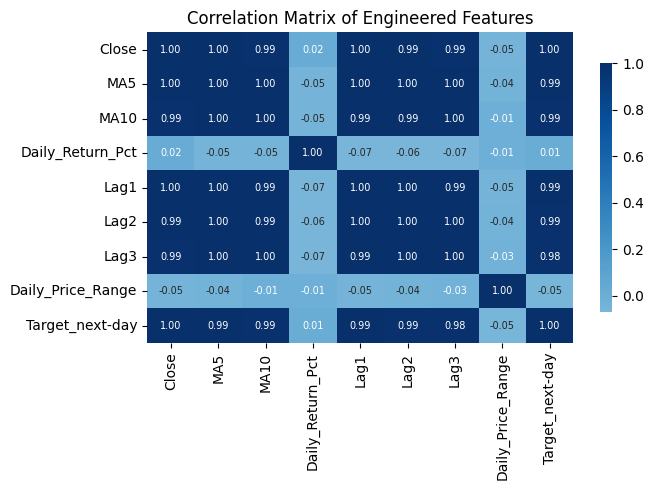

In [13]:
#----------------------------------------------------
#Plot 3: Correlation matrix of engineered features
#----------------------------------------------------
feature_cols = ["Close", "MA5", "MA10", "Daily_Return_Pct", "Lag1", "Lag2", "Lag3",
             "Daily_Price_Range", "Target_next-day"]
corr = df[feature_cols].corr()
fig, ax = plt.subplots(figsize = (7, 5))
sns.heatmap(corr, annot = True, fmt = ".2f", cmap = "Blues", center = 0, ax = ax,
            annot_kws = {"size": 7}, cbar_kws = {"shrink": 0.8})
ax.set_title("Correlation Matrix of Engineered Features")
fig.tight_layout()
fig.savefig("C:/Users/kitso/plot3_correlation.png")
plt.show()

## 3. Model training

In [14]:
#-----------------------------------------------------
#Get the feature matrix (X) and target variable (y)
#-----------------------------------------------------
features = ["MA5", "MA10", "Daily_Return_Pct", "Lag1", "Lag2", "Lag3", "Daily_Price_Range"]
target = "Target_next-day"

X = df[features].values
y = df[target].values
dates = df["Date"].values #This takes the Date column and stores it separately so it can later identify which dates correspond to the predictions.

In [15]:
#---------------------------------------------------------------------------------------------------------
#80/20 train-test data split
#Set the first 80% of the historical observations for training and the most recent 20% for testing.
#---------------------------------------------------------------------------------------------------------
split_index = int(len(X) * 0.8)

X_train = X[:split_index]
X_test = X[split_index:]

y_train = y[:split_index]
y_test = y[split_index:]

dates_train = dates[:split_index]
dates_test = dates[split_index:]

print(f"Train size: {len(X_train)} ({dates_train[0]} to {dates_train[-1]})")
print(f"Test size:  {len(X_test)} ({dates_test[0]} to {dates_test[-1]})")

Train size: 432 (2024-01-16T00:00:00.000000 to 2025-10-03T00:00:00.000000)
Test size:  108 (2025-10-06T00:00:00.000000 to 2026-03-11T00:00:00.000000)


#### TIME-SERIES CROSS-VALIDATION TO TUNE RANDOM FOREST
The main goal in tuning the Random Forest is to find the best value for max_depth. This tries several different Random Forest depths, tests each one on multiple time-ordered validation periods, calculates the RMSE, and chooses the depth that gives the lowest average RMSE.

In [16]:
#--------------------------------------------------------------------------------
#TIME-SERIES CROSS-VALIDATION TO TUNE RANDOM FOREST
#--------------------------------------------------------------------------------
tscv = TimeSeriesSplit(n_splits = 5) #This creates 5 time-series cross-validation folds.
depth_candidates = [3, 5, 8, 10, None] #Define the possible tree depths
cv_results = {} #An empty set is created to store the results


for depth in depth_candidates:
    fold_rmse = []
    for tr_idx, val_idx in tscv.split(X_train):
        rf_cv = RandomForestRegressor(n_estimators = 100, max_depth = depth, random_state = 42) #Create the Random Forest model
        rf_cv.fit(X_train[tr_idx], y_train[tr_idx]) #Train the Random Forest
        pred = rf_cv.predict(X_train[val_idx]) #Predict the validation period

        #Calculate RMSE - It measures how far the model's predictions are from the actual S&P 500 closing prices.
        fold_rmse.append(np.sqrt(mean_squared_error(y_train[val_idx], pred))) 
    cv_results[str(depth)] = np.mean(fold_rmse)

#Print the results
print("Time-series cross-validation mean RMSE by max_depth:")
for d, r in cv_results.items():
    print(f" max_depth={d}: RMSE={r:.4f}")

Time-series cross-validation mean RMSE by max_depth:
 max_depth=3: RMSE=227.4064
 max_depth=5: RMSE=220.9086
 max_depth=8: RMSE=220.1768
 max_depth=10: RMSE=219.2220
 max_depth=None: RMSE=219.4480


**Findings**: Based on time-series cross-validation, a Random Forest with max_depth = 10 produced the lowest average RMSE among the depths tested.

#### TRAIN THE FINAL MODELS

In [17]:
#-----------------------------------
#TRAIN THE FINAL MODELS
#-----------------------------------
#Linear Regression model
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)

In [18]:
#Random Forest model
rf = RandomForestRegressor(n_estimators = 100, max_depth = 10, random_state = 42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

## 4. Model evaluation 
Measure how well each model performed on the test data

As stated in the proposal, three evaluation metrics will be used:
* RMSE: measures how large the prediction errors are (Low RMSE = Good model)
* MAE: measures the average absolute prediction error (Low MAE = Good model)
* R^2: measures how well the model explains variation in the target (Closer to 1 = Good predictions)

In [19]:
#---------------------------------------------------------------------------------------------------------------------------------------------------
#Create a function for the three evaluation metrics 
#The function called metrics() is created to avoid having to write the same evaluation code separately for Linear Regression and Random Forest.
#---------------------------------------------------------------------------------------------------------------------------------------------------
def metrics(y_actual, y_pred):
    rmse = np.sqrt(mean_squared_error(y_actual, y_pred)) #Calculate the RMSE
    mae = mean_absolute_error(y_actual, y_pred) #Calculate the MAE
    r2 = r2_score(y_actual, y_pred) #Calculate the R^2
    return rmse, mae, r2

#### Evaluate Linear Regression

In [20]:
#--------------------------------------
#Evaluate Linear Regression
#--------------------------------------
rmse_lr, mae_lr, r2_lr = metrics(y_test, pred_lr)

#### Evaluate Random Forest

In [21]:
#--------------------------------------
#Evaluate Random Forest
#--------------------------------------
rmse_rf, mae_rf, r2_rf = metrics(y_test, pred_rf)

In [22]:
#----------------------------------------------
#Create a results table
#----------------------------------------------
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "RMSE": [rmse_lr, rmse_rf],
    "MAE": [mae_lr, mae_rf],
    "R^2": [r2_lr, r2_rf]
})

print("== Test set performance ==")
print(results.round(4).to_string(index = False))

== Test set performance ==
            Model     RMSE      MAE     R^2
Linear Regression  56.8113  44.0628  0.6816
    Random Forest 156.5281 138.0635 -1.4171


**Findings**: We can clearly see that Linear Regression outperformed Random Forest. Linear Regression has the lowest RMSE and MAE and achieved a coefficient of determination (R^2) of 0.6816. 

## 5. Hypothesis testing
#### Hypothesis 1 (model performance comparison): paired-sample t-test on absolute residuals


In [23]:
#------------------------------------------------------------------------------------------------------
#Hypothesis 1 (model performance comparison): paired-sample t-test on absolute residuals
#------------------------------------------------------------------------------------------------------
lr_residual = np.abs(y_test - pred_lr)
rf_residual = np.abs(y_test - pred_rf)

t_stat, p_val = stats.ttest_rel(lr_residual, rf_residual)

print(f"H1 paired t-test LR vs RF): t = {t_stat:.4f}, p = {p_val:.4f}")
H1_conclusion = "Reject H0 (significant difference)" if p_val < 0.05 else "Fail to reject H0 (no significant difference)"
print(f"Conclusion: {H1_conclusion}")

H1 paired t-test LR vs RF): t = -10.9560, p = 0.0000
Conclusion: Reject H0 (significant difference)


**Findings**: The paired t-test on absolute residuals was significant (p < 0.05), so H0 is rejected. In the proposal, the alternative hypothesis states that Random Forest Regression demonstrates statistically significantly better predictive performance than Linear Regression, but according to the results obtained from the paired t-test, Linear Regression outperformed Random Forest Regression, which is the opposite of what is stated in the proposal. This happened because the test period (October 2025–March 2026) saw the S&P 500 reach new record highs that were above the values observed during training. This created a problem for the Random Forest model because tree-based models are generally unable to predict values outside the range of the training data. Instead, their predictions are based on averages of values they have already seen. As a result, the Random Forest predictions remained close to the upper end of the training range while the actual index continued to increase. This highlights an important limitation of Random Forest models when working with financial time series that show strong upward trends, and it is relevant to the Statistical Learning Theory discussion in the proposal.

#### Hypothesis 2 (feature importance and model development): ablation 
The S&P 500 index-level FRED data does not provide the full OHLCV information; therefore, Lag1 will be used as the baseline.

In [24]:
#------------------------------------------------------------------------------------------------------
#Hypothesis 2 (feature importance and model development): ablation
#The S&P 500 index-level FRED data does not provide the full OHLCV information; therefore, Lag1 will be used as the baseline.
#------------------------------------------------------------------------------------------------------
lr_residual = np.abs(y_test - pred_lr)
X_base_train, X_base_test = X_train[:, [3]], X_test[:, [3]]  # Lag1 column

In [25]:
lr_baseline = LinearRegression().fit(X_base_train, y_train)
rf_baseline = RandomForestRegressor(n_estimators = 100, max_depth = 10, random_state = 42).fit(X_base_train, y_train)

In [26]:
pred_lr_baseline = lr_baseline.predict(X_base_test)
pred_rf_baseline = rf_baseline.predict(X_base_test)

In [27]:
rmse_lr_b, mae_lr_b, r2_lr_b = metrics(y_test, pred_lr_baseline)
rmse_rf_b, mae_rf_b, r2_rf_b = metrics(y_test, pred_rf_baseline)

In [28]:
ablation = pd.DataFrame({
    "Model": ["Linear Regression (baseline: Lag1 only)", "Linear Regression (full 7 features)",
              "Random Forest (baseline: Lag1 only)", "Random Forest (full 7 features)"],
    "RMSE": [rmse_lr_b, rmse_lr, rmse_rf_b, rmse_rf],
    "MAE": [mae_lr_b, mae_lr, mae_rf_b, mae_rf],
    "R2": [r2_lr_b, r2_lr, r2_rf_b, r2_rf]
})

print("== Ablation: baseline vs full feature set ==")
print(ablation.round(4).to_string(index = False))

== Ablation: baseline vs full feature set ==
                                  Model     RMSE      MAE      R2
Linear Regression (baseline: Lag1 only)  71.7074  57.1183  0.4927
    Linear Regression (full 7 features)  56.8113  44.0628  0.6816
    Random Forest (baseline: Lag1 only) 145.2854 127.2255 -1.0824
        Random Forest (full 7 features) 156.5281 138.0635 -1.4171


In [29]:
resid_rf_base = np.abs(y_test - pred_rf_baseline)
resid_rf_full = np.abs(y_test - pred_rf)

t_stat2, p_val2 = stats.ttest_rel(resid_rf_base, resid_rf_full)

print(f"H2 paired t-test (RF baseline vs RF full): t = {t_stat2:.4f}, p = {p_val2:.4f}")
H2_conclusion = "Reject H0 (engineered features significantly improve accuracy)" if p_val2 < 0.05 else "Fail to reject H0 (no significant improvement)"
print(f"Conclusion: {H2_conclusion}")

H2 paired t-test (RF baseline vs RF full): t = -5.3839, p = 0.0000
Conclusion: Reject H0 (engineered features significantly improve accuracy)


**Findings**: The paired t-test on absolute residuals was significant (p < 0.05), so H0 is rejected. In the proposal, the alternative hypothesis states that engineering features significantly improve the predictive accuracy of the Random Forest Regression model and are among the most important predictors, but according to the results obtained, adding the seven engineering features increased the Random Forest's RMSE (145.2854 >> 156.5281) while they improved the Linear Regression's RMSE (71.7074 >> 56.8113). This suggests that engineered features helped the simpler model generalise but added complexity for the ensemble model under this specific market regime.

## 6. Feature importance
Find out which features were most important to the Random Forest when making its predictions.

In [30]:
#------------------------------------------------------
#Create a table for Random Forest feature importance
#------------------------------------------------------
importances = pd.DataFrame({
    "Feature": features,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False) #Sort the features from most important to least important

print("== Random Forest Feature Importance ==")
print(importances.round(4).to_string(index = False))

== Random Forest Feature Importance ==
          Feature  Importance
             Lag1      0.5032
              MA5      0.3896
             Lag2      0.0434
             MA10      0.0430
             Lag3      0.0100
 Daily_Return_Pct      0.0078
Daily_Price_Range      0.0029


## 7. Plots
#### Actual vs Predicted 
This plot compares the actual S&P 500 closing prices, the Linear Regression predictions, and the Random Forest predictions.

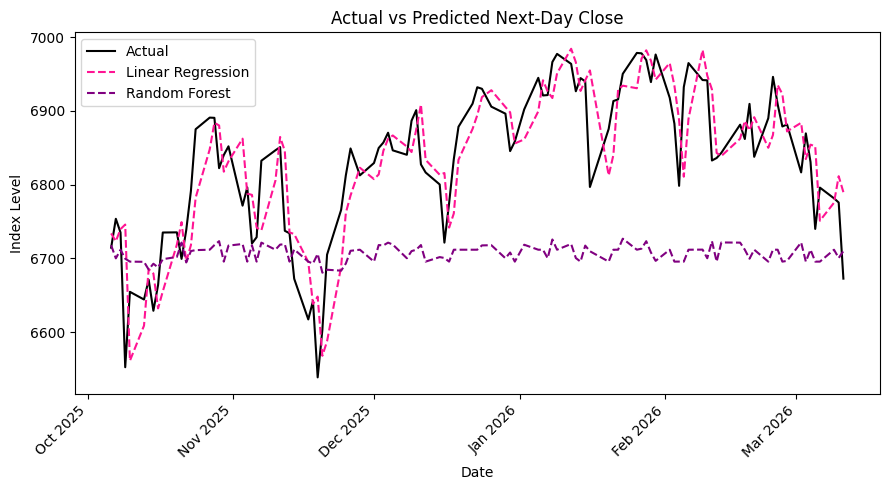

In [31]:
fig, ax = plt.subplots(figsize = (9, 5))
ax.plot(dates_test, y_test, label = "Actual", color = "black")
ax.plot(dates_test, pred_lr, label = "Linear Regression", color = "deeppink", linestyle = "--")
ax.plot(dates_test, pred_rf, label = "Random Forest", color = "purple", linestyle = "--")
ax.set_title("Actual vs Predicted Next-Day Close")
ax.set_xlabel("Date")
ax.set_ylabel("Index Level")
ax.legend()

# Format dates on x-axis
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

# Rotate date labels
plt.setp(ax.get_xticklabels(), rotation = 45, ha = "right")

fig.tight_layout()
plt.show()

**Findings**: The Random Forest predictions flatten out while the actual S&P 500 continues rising. The Random Forest struggles to extrapolate beyond the range it observed during training.

#### Scatter plot: actual vs predicted

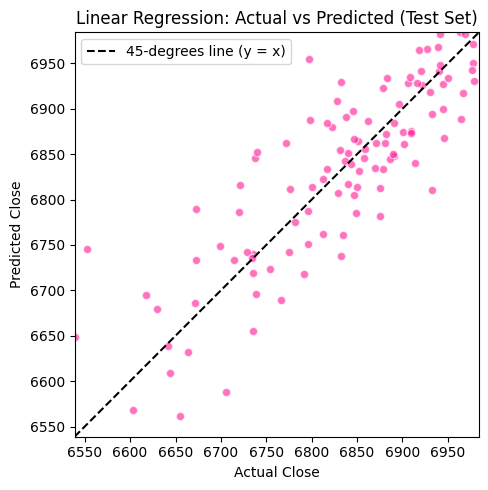

In [32]:
#------------------------------------------------------
#Scatter plot: actual vs predicted
#------------------------------------------------------

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_test, pred_lr, alpha = 0.6, color="deeppink", edgecolor="white")

# 45-degree line (y = x)
lims = [min(y_test.min(), pred_lr.min()), max(y_test.max(), pred_lr.max())]
ax.plot(lims, lims, color="black", linestyle="--", label="45-degrees line (y = x)")

ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Actual Close")
ax.set_ylabel("Predicted Close")
ax.set_title("Linear Regression: Actual vs Predicted (Test Set)")
ax.set_aspect("equal", adjustable = "box")
ax.legend()
fig.tight_layout()
fig.savefig("C:/Users/kitso/plot_scatter.png")
plt.show()

#### Residual distribution comparison
This plot tells you about the distribution and behaviour of errors.

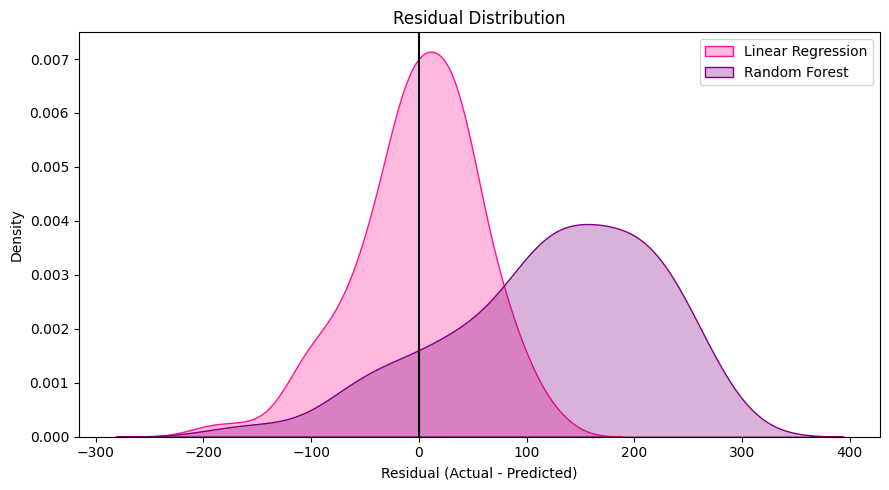

In [33]:
#-------------------------------------------------
#Residual distribution comparison
#-------------------------------------------------
fig, ax = plt.subplots(figsize = (9, 5))
sns.kdeplot(y_test - pred_lr, label = "Linear Regression", fill = True, alpha = 0.3, ax = ax, color = "deeppink")
sns.kdeplot(y_test - pred_rf, label = "Random Forest", fill = True, alpha = 0.3, ax = ax, color = "purple")
ax.axvline(0, color = "black")
ax.set_title("Residual Distribution")
ax.set_xlabel("Residual (Actual - Predicted)")
ax.legend()
fig.tight_layout()
fig.savefig("C:/Users/kitso/plot_residual.png")
plt.show()

**Findings**: Linear Regression has a narrow distribution, which suggests that the predictions tend to be closer to the actual values. The Linear Regression distribution is more tightly concentrated around zero, which provides visual evidence that its predictions are generally closer to the actual values, supporting the RMSE and MAE results.

#### Feature importance bar chart

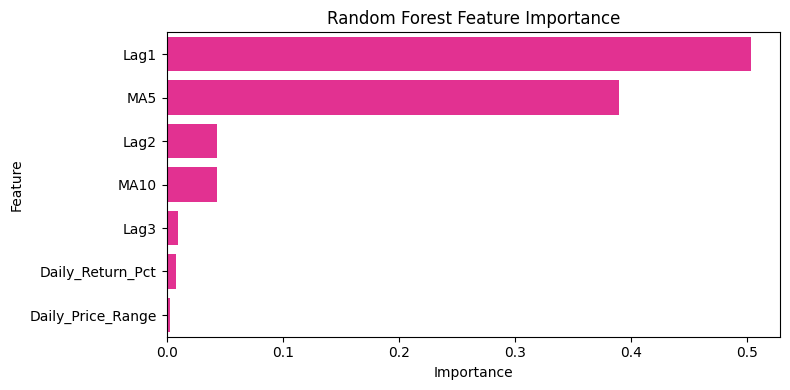

In [34]:
#-----------------------------------------
#Feature importance bar chart
#-----------------------------------------
fig, ax = plt.subplots(figsize = (8, 4))
sns.barplot(data = importances, y = "Feature", x = "Importance", ax = ax, color = "deeppink")
ax.set_title("Random Forest Feature Importance")
fig.tight_layout()
fig.savefig("C:/Users/kitso/plot_feature.png")
plt.show()

**Findings**: Lag1 is the most important feature, suggesting that the previous closing price contains most of the predictive information used by the Random Forest.

#### Q-Q plot of Linear Regression residuals (check for normality)

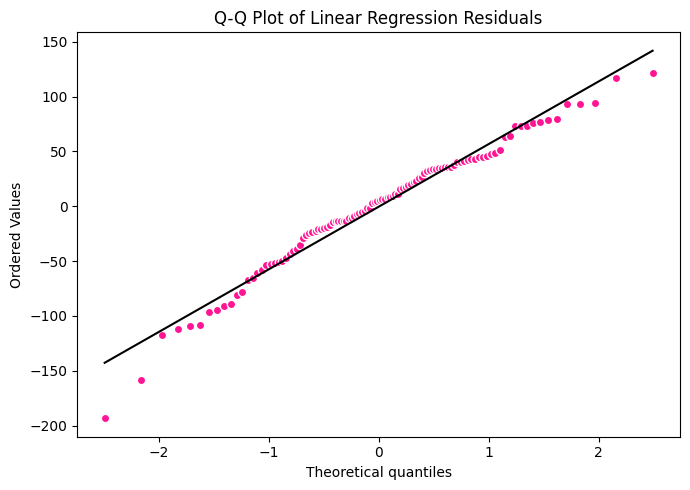

In [35]:
#------------------------------------------------------------------
#Q-Q plot of Linear Regression residuals (check for normality)
#------------------------------------------------------------------
resid_lr_vals = y_test - pred_lr
fig, ax = plt.subplots(figsize = (7, 5))
stats.probplot(resid_lr_vals, dist = "norm", plot = ax)
ax.set_title("Q-Q Plot of Linear Regression Residuals")
ax.get_lines()[0].set_markerfacecolor("deeppink")
ax.get_lines()[0].set_markeredgecolor("white")
ax.get_lines()[1].set_color("black")  #The reference line
fig.tight_layout()
fig.savefig("C:/Users/kitso/plot_QQ.png")
plt.show()

**Findings:** The Q–Q plot shows that the Linear Regression residuals approximately follow the normal distribution in the centre of the distribution, but substantial deviations occur in both tails. This indicates the presence of heavier-tailed residuals and some extreme prediction errors. Therefore, the residuals do not appear to be perfectly normally distributed. This suggests that the model occasionally produces unusually large prediction errors, which may reflect the difficulty of predicting large movements in the S&P 500.

#### Performance metrics comparison table

MSE  -> LR: 3227.5223   RF: 24501.0355
Directional Accuracy -> LR: 78.7037%   RF: 52.7778%


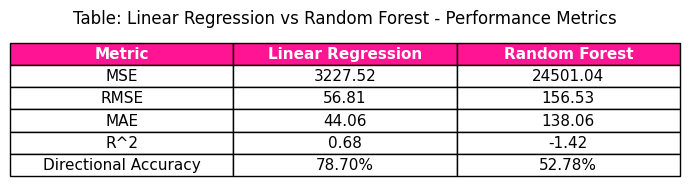

In [36]:
#-------------------------------------------------
#Performance metrics comparison table 
#-------------------------------------------------

#Directional accuracy: did the model correctly predict up/down movement vs previous close?
actual_direction = np.sign(y_test - X_test[:, 3])       #Use Lag1
pred_lr_direction = np.sign(pred_lr - X_test[:, 3])
pred_rf_direction = np.sign(pred_rf - X_test[:, 3])

dir_acc_lr = (actual_direction == pred_lr_direction).mean() * 100
dir_acc_rf = (actual_direction == pred_rf_direction).mean() * 100

mse_lr = rmse_lr ** 2
mse_rf = rmse_rf ** 2

print(f"MSE  -> LR: {mse_lr:.4f}   RF: {mse_rf:.4f}")
print(f"Directional Accuracy -> LR: {dir_acc_lr:.4f}%   RF: {dir_acc_rf:.4f}%")

fig, ax = plt.subplots(figsize = (7, 2))
ax.axis("off")

table_data = [
    ["Metric", "Linear Regression", "Random Forest"],
    ["MSE", f"{mse_lr:.2f}", f"{mse_rf:.2f}"],
    ["RMSE", f"{rmse_lr:.2f}", f"{rmse_rf:.2f}"],
    ["MAE", f"{mae_lr:.2f}", f"{mae_rf:.2f}"],
    ["R^2", f"{r2_lr:.2f}", f"{r2_rf:.2f}"],
    ["Directional Accuracy", f"{dir_acc_lr:.2f}%", f"{dir_acc_rf:.2f}%"]
]

tbl = ax.table(cellText = table_data, cellLoc = "center", loc = "center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(11)
tbl.scale(1, 1.8)

#Style header row
for col in range(3):
    cell = tbl[0, col]
    cell.set_facecolor("deeppink")
    cell.set_text_props(color = "white", weight = "bold")

ax.set_title("Table: Linear Regression vs Random Forest - Performance Metrics\n")
fig.tight_layout()
fig.savefig("C:/Users/kitso/plot_comparison.png")
plt.show()

## 8. Refined models
**Diagnosis**: Random Forest is a tree-based model, so its predictions are limited by the target values it sees during training. Because its leaf nodes predict averages of observed values, it cannot extrapolate beyond the training range.In this case, the test period (October 2025–March 2026) saw the S&P 500 reach new all-time highs that were above the values in the training data. As a result, Random Forest could not predict these higher prices effectively. This was a structural limitation of the model, rather than a problem that could be solved simply by further hyperparameter tuning.

**Fix**: Predict the next-day percentage return instead of the absolute price level, then reconstruct the price as today's_close × (1 + predicted_return). Returns are stationary (no trend to extrapolate), which removes the structural cause of Random Forest's underperformance. Random Forest hyperparameters (n_estimators, max_depth, min_samples_leaf, max_features) were re-tuned via GridSearchCV with TimeSeriesSplit cross-validation on the return target.

In [37]:
#Get the feature matrix (X) and target variable (y)
features = ["MA5", "MA10", "Daily_Return_Pct", "Lag1", "Lag2", "Lag3", "Daily_Price_Range"]

# NEW TARGET: next-day % return, instead of next-day absolute close
df["Target_Return"] = (df["Target_next-day"] - df["Close"]) / df["Close"] * 100

X = df[features].values
y_return = df["Target_Return"].values
y_price = df["Target_next-day"].values
today_close = df["Close"].values
dates = df["Date"].values

In [38]:
#------------------------------------------------------
#80/20 train-test-split
#------------------------------------------------------
split_idx = int(len(df) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_return_train, y_return_test = y_return[:split_idx], y_return[split_idx:]
y_price_test = y_price[split_idx:]
today_close_test = today_close[split_idx:]

In [39]:
#------------------------------------------------------
#Hyperparameter tuning for RF on the RETURN target
#------------------------------------------------------
tscv = TimeSeriesSplit(n_splits=5)
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, 8, None],
    "min_samples_leaf": [1, 5, 10],
    "max_features": ["sqrt", 1.0],
}
grid = GridSearchCV(RandomForestRegressor(random_state = 42), param_grid,
                     cv = tscv, scoring = "neg_root_mean_squared_error", n_jobs = -1)
grid.fit(X_train, y_return_train)
print("Best RF params (on return target):", grid.best_params_)
rf = grid.best_estimator_

Best RF params (on return target): {'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'n_estimators': 200}


In [40]:
lr = LinearRegression().fit(X_train, y_return_train)

In [41]:
pred_return_lr = lr.predict(X_test)
pred_return_rf = rf.predict(X_test)

In [42]:
#------------------------------------------------------
#Reconstruct price predictions from predicted returns
#------------------------------------------------------
pred_price_lr = today_close_test * (1 + pred_return_lr / 100)
pred_price_rf = today_close_test * (1 + pred_return_rf / 100)

def metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return rmse, mae, r2

print("Price-level metrics (reconstructed from predicted returns)")
for name, pred in [("Linear Regression", pred_price_lr), ("Random Forest", pred_price_rf)]:
    rmse, mae, r2 = metrics(y_price_test, pred)
    print(f"{name:20s} RMSE={rmse:.2f}  MAE={mae:.2f}  R2={r2:.3f}")

print("\nReturn-level metrics (%)")
for name, pred in [("Linear Regression", pred_return_lr), ("Random Forest", pred_return_rf)]:
    rmse, mae, r2 = metrics(df["Target_Return"].values[split_idx:], pred)
    print(f"{name:20s} RMSE={rmse:.3f}  MAE={mae:.3f}  R2={r2:.3f}")

Price-level metrics (reconstructed from predicted returns)
Linear Regression    RMSE=57.32  MAE=44.91  R2=0.676
Random Forest        RMSE=54.05  MAE=40.97  R2=0.712

Return-level metrics (%)
Linear Regression    RMSE=0.844  MAE=0.660  R2=-0.137
Random Forest        RMSE=0.795  MAE=0.602  R2=-0.009


In [43]:
#------------------------------------------------------
#Directional accuracy
#------------------------------------------------------
actual_dir = np.sign(y_price_test - today_close_test)
lr_dir = np.sign(pred_price_lr - today_close_test)
rf_dir = np.sign(pred_price_rf - today_close_test)
print(f"Directional accuracy -> LR: {(actual_dir==lr_dir).mean()*100:.1f}%  RF: {(actual_dir==rf_dir).mean()*100:.1f}%")

resid_lr = np.abs(y_price_test - pred_price_lr)
resid_rf = np.abs(y_price_test - pred_price_rf)
t_stat, p_val = stats.ttest_rel(resid_lr, resid_rf)
print(f"\nPaired t-test |residuals| LR vs RF: t={t_stat:.4f}, p={p_val:.4f}")

Directional accuracy -> LR: 48.1%  RF: 50.0%

Paired t-test |residuals| LR vs RF: t=3.0344, p=0.0030


MSE  -> LR: 3285.5208   RF: 2921.5671
Directional Accuracy -> LR: 48.1481%   RF: 50.0000%


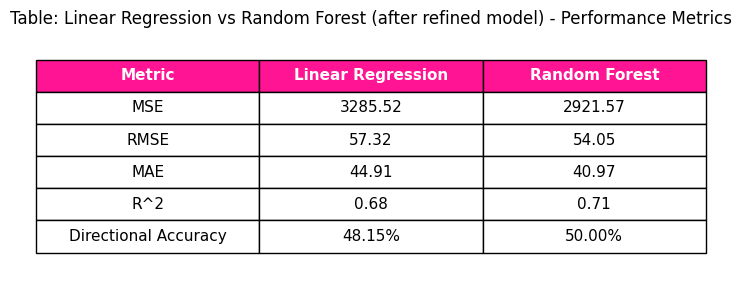

In [44]:
#-------------------------------------------------
#Performance metrics comparison table 
#-------------------------------------------------
lr_rmse = np.sqrt(mean_squared_error(y_price_test, pred_price_lr))
rf_rmse = np.sqrt(mean_squared_error(y_price_test, pred_price_rf))

lr_mse = lr_rmse ** 2
rf_mse = rf_rmse ** 2

lr_mae = mean_absolute_error(y_price_test, pred_price_lr)
rf_mae = mean_absolute_error(y_price_test, pred_price_rf)

lr_R2 = r2_score(y_price_test, pred_price_lr)
rf_R2 = r2_score(y_price_test, pred_price_rf)

lr_dir_acc = (actual_dir == lr_dir).mean() * 100
rf_dir_acc = (actual_dir == rf_dir).mean() * 100

print(f"MSE  -> LR: {lr_mse:.4f}   RF: {rf_mse:.4f}")
print(f"Directional Accuracy -> LR: {lr_dir_acc:.4f}%   RF: {rf_dir_acc:.4f}%")

fig, ax = plt.subplots(figsize = (7, 3))
ax.axis("off")

table_data = [
    ["Metric", "Linear Regression", "Random Forest"],
    ["MSE", f"{lr_mse:.2f}", f"{rf_mse:.2f}"],
    ["RMSE", f"{lr_rmse:.2f}", f"{rf_rmse:.2f}"],
    ["MAE", f"{lr_mae:.2f}", f"{rf_mae:.2f}"],
    ["R^2", f"{lr_R2:.2f}", f"{rf_R2:.2f}"],
    ["Directional Accuracy", f"{lr_dir_acc:.2f}%", f"{rf_dir_acc:.2f}%"]
]

tbl = ax.table(cellText = table_data, cellLoc = "center", loc = "center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(11)
tbl.scale(1, 1.8)

#Style header row
for col in range(3):
    cell = tbl[0, col]
    cell.set_facecolor("deeppink")
    cell.set_text_props(color = "white", weight = "bold")

ax.set_title("Table: Linear Regression vs Random Forest (after refined model) - Performance Metrics")
fig.tight_layout()
fig.savefig("C:/Users/kitso/plot_comparison_new.png")
plt.show()

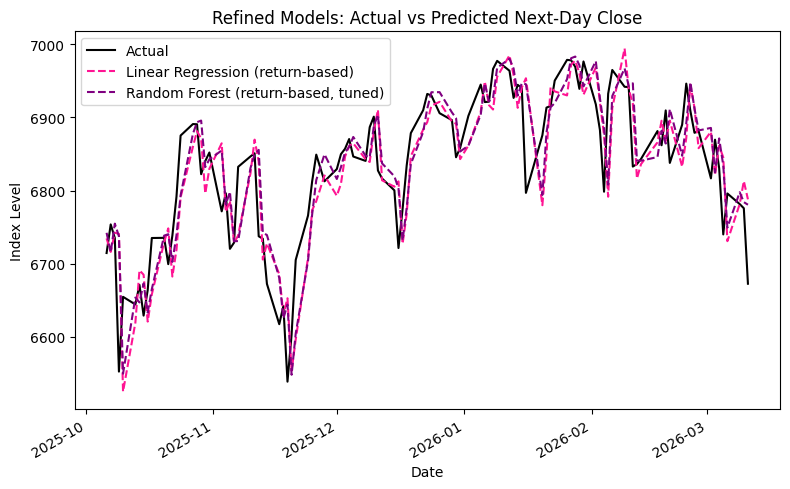

In [45]:
#----------------------------------------------
# Actual vs. Predicted: Refined models
#----------------------------------------------
dates_test = dates[split_idx:]
fig, ax = plt.subplots(figsize = (8, 5))
ax.plot(dates_test, y_price_test, label = "Actual", color = "black")
ax.plot(dates_test, pred_price_lr, label = "Linear Regression (return-based)", color = "deeppink", linestyle="--")
ax.plot(dates_test, pred_price_rf, label = "Random Forest (return-based, tuned)", color = "purple", linestyle="--")
ax.set_title("Refined Models: Actual vs Predicted Next-Day Close")
ax.set_xlabel("Date")
ax.set_ylabel("Index Level")
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## 8. Analytical Procedure and Tools
All analysis was conducted in Python 3.x in a Jupyter Notebook, as stated in the proposal. Data was split chronologically 80/20 (432 training rows to 6 October 2025; 108 test rows through 12 March 2026) to avoid look-ahead bias. Random Forest's max_depth was tuned via 5-fold TimeSeriesSplit cross-validation (best: depth = 10, n_estimators = 100, random_state = 42). Both models predicted the next-day close; performance was compared using RMSE, MAE, and R², and a paired-sample t-test on absolute residuals tested Hypothesis 1. An ablation (baseline vs. full 7-feature set) tested Hypothesis 2, and Random Forest feature importance was extracted.

## 9. Challenges encountered
The main challenge was the availability and level of detail in the index data. The Kaggle dataset was outdated and only provided closing prices, so FRED data had to be added, and the Daily Price Range feature had to be adapted using the information available. A more important challenge was identified from the results: the Random Forest could not predict values beyond the range it had seen during training. As a result, its performance declined sharply, including a negative R^2. This was a limitation of the model rather than a coding error. 